# 💳 *Financial Transaction Fraud Detection & Pattern Analysis*

#### A Machine Learning Approach Using Supervised and Unsupervised Learning

---

**Course:** CSD 302 — Machine Learning  
**Project Type:** Individual Course Project  
**Domain:** Financial Fraud Detection  
**Dataset:** BankSim — Synthetic Financial Transaction Dataset

## 🎯 Problem Statement
Financial fraud is a critical challenge in digital payment systems, where fraudulent transactions are typically much less frequent than legitimate ones and may exhibit complex transaction patterns.

This project aims to develop an **end-to-end machine learning framework** that:

- 🔍 **Detects fraudulent financial transactions** using supervised learning while addressing class imbalance and preventing data leakage.
- 📊 **Compares multiple classification models** using appropriate metrics such as *Precision, Recall, F1-score, ROC-AUC,* and *Precision-Recall AUC*.
- ⚙️ **Optimizes model performance** through stratified cross-validation, hyperparameter tuning, and decision-threshold analysis.
- 🧩 **Discovers natural transaction patterns** using unsupervised learning without using fraud labels during clustering.
- 📈 **Analyzes the discovered clusters** to determine whether certain transaction patterns are associated with different concentrations of fraudulent activity.
- ⚖️ **Examines practical and ethical considerations**, including class imbalance, false positives, false negatives, privacy, bias, and limitations of the dataset.

> **Overall Goal:** Build and evaluate a reliable machine learning framework for *fraud detection and transaction pattern analysis* while maintaining an honest and interpretable evaluation of model performance.

## 📊 Dataset Description

### BankSim Dataset

The project uses the **BankSim** dataset, a synthetic financial transaction dataset generated using a payment simulator designed to reproduce characteristics of real-world banking transactions.

The dataset contains approximately **594,643 transactions**, including both legitimate and fraudulent transactions.

### Main Features

| Feature | Description | Type |
|---|---|---|
| `step` | Time step associated with the transaction | Numerical |
| `customer` | Customer identifier | Identifier |
| `age` | Customer age group | Categorical |
| `gender` | Customer gender | Categorical |
| `zipcodeOri` | Origin ZIP code | Categorical/Identifier |
| `merchant` | Merchant identifier | Identifier |
| `zipMerchant` | Merchant ZIP code | Categorical/Identifier |
| `category` | Transaction category | Categorical |
| `amount` | Transaction amount | Numerical |
| `fraud` | Fraud indicator: 0 = legitimate, 1 = fraudulent | Target |

### Important Dataset Characteristics

- The target variable is `fraud`.
- Fraudulent transactions form a minority class.
- The dataset contains both numerical and categorical variables.
- Several columns represent customers, merchants, or locations and therefore require careful treatment during preprocessing.
- The dataset is synthetic, which should be considered when interpreting the results and discussing limitations.

## ⚠️ Important Evaluation Principle

Fraud detection is an **imbalanced classification problem** because legitimate transactions substantially outnumber fraudulent transactions.

Therefore, **accuracy alone is not an appropriate measure of model quality**.

For example, a model could classify almost every transaction as legitimate and still achieve a high accuracy while failing to detect fraudulent transactions.

Therefore, this project will primarily focus on:

- **Precision** — How many transactions predicted as fraud were actually fraudulent?
- **Recall** — How many actual fraudulent transactions were successfully detected?
- **F1-score** — Balance between precision and recall.
- **ROC-AUC** — Ability of the model to distinguish between the two classes across thresholds.
- **PR-AUC / Average Precision** — Particularly informative when the positive class is rare.

The final model will also be evaluated using a **confusion matrix** and decision-threshold analysis.

## 🛠️ 1. Importing Required Libraries

We begin by importing the Python libraries required for data loading, manipulation, visualization, and machine learning.

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

## 📥 2. Loading the Dataset

The raw BankSim transaction dataset is stored as a CSV file in the project directory.

We load the dataset into a Pandas DataFrame so that it can be inspected, cleaned, visualized, and subsequently used for machine learning.

> **Important:** The raw dataset will be treated as the original source data. We will avoid modifying the raw CSV directly and will perform cleaning and transformations within the notebook.

In [3]:
data_path = Path("bs140513_032310.csv")

df = pd.read_csv(data_path)

print("Dataset loaded successfully.")

Dataset loaded successfully.


## 🔎 3. Initial Dataset Inspection

Before performing any cleaning or preprocessing, we first inspect the basic structure of the dataset.

In [4]:
print(f"Number of rows    : {df.shape[0]:,}")
print(f"Number of columns : {df.shape[1]}")

Number of rows    : 594,643
Number of columns : 10


In [5]:
df.head()

,step,customer,age,gender,zipcodeOri,merchant,zipMerchant,category,amount,fraud
0,0,'C1093826151','4','M','28007','M348934600','28007','es_transportation',4.55,0
1,0,'C352968107','2','M','28007','M348934600','28007','es_transportation',39.68,0
2,0,'C2054744914','4','F','28007','M1823072687','28007','es_transportation',26.89,0
3,0,'C1760612790','3','M','28007','M348934600','28007','es_transportation',17.25,0
4,0,'C757503768','5','M','28007','M348934600','28007','es_transportation',35.72,0


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 594643 entries, 0 to 594642
Data columns (total 10 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   step         594643 non-null  int64  
 1   customer     594643 non-null  object 
 2   age          594643 non-null  object 
 3   gender       594643 non-null  object 
 4   zipcodeOri   594643 non-null  object 
 5   merchant     594643 non-null  object 
 6   zipMerchant  594643 non-null  object 
 7   category     594643 non-null  object 
 8   amount       594643 non-null  float64
 9   fraud        594643 non-null  int64  
dtypes: float64(1), int64(2), object(7)
memory usage: 45.4+ MB


In [8]:
df.describe(include="all")

,step,customer,age,gender,zipcodeOri,merchant,zipMerchant,category,amount,fraud
count,594643.000000,594643,594643,594643,594643,594643,594643,594643,594643.000000,594643.000000
unique,NaN,4112,8,4,1,50,1,15,NaN,NaN
top,NaN,'C1978250683','2','F','28007','M1823072687','28007','es_transportation',NaN,NaN
freq,NaN,265,187310,324565,594643,299693,594643,505119,NaN,NaN
mean,94.986827,NaN,NaN,NaN,NaN,NaN,NaN,NaN,37.890135,0.012108
std,51.053632,NaN,NaN,NaN,NaN,NaN,NaN,NaN,111.402831,0.109369
min,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000
25%,52.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13.740000,0.000000
50%,97.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,26.900000,0.000000
75%,139.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,42.540000,0.000000


### 📝 Key Takeaway

The BankSim dataset contains **594,643 transactions and 10 variables**.

The initial inspection shows that:

- There are **no missing values** in any column.
- The dataset contains numerical, categorical, and identifier-style variables.
- `fraud` is a binary target variable.
- Only approximately **1.21% of transactions are fraudulent**, confirming that this is a highly imbalanced classification problem.
- `amount` shows substantial variation, while variables such as `customer`, `merchant`, and location codes represent entities rather than ordinary numerical measurements.


## 🧹 4. Data Cleaning & Quality Checks

### Checking Missing Values

In [9]:
missing_values = df.isnull().sum()
print(f"Total missing values: {missing_values.sum():,}")

Total missing values: 0


### Checking duplicate records

In [10]:
duplicate_count = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicate_count:,}")

Number of duplicate rows: 0


### Target Validation

In [11]:
print("Unique values in fraud column:")
print(sorted(df["fraud"].unique()))
print("\nFraud value counts:")
print(df["fraud"].value_counts())

Unique values in fraud column:
[np.int64(0), np.int64(1)]

Fraud value counts:
fraud
0    587443
1      7200
Name: count, dtype: int64


### Categorical Inspection

In [11]:
categorical_columns = [
    "age",
    "gender",
    "category"
]

for col in categorical_columns:
    print(f"\n{'=' * 50}")
    print(f"{col}")
    print(f"{'=' * 50}")
    print(df[col].value_counts())

print("Step range:")
print(f"Minimum: {df['step'].min()}")
print(f"Maximum: {df['step'].max()}")

print("\nAmount range:")
print(f"Minimum: {df['amount'].min()}")
print(f"Maximum: {df['amount'].max()}")
print("\nNumber of negative transaction amounts:", (df["amount"] < 0).sum())


age
age
'2'    187310
'3'    147131
'4'    109025
'5'     62642
'1'     58131
'6'     26774
'0'      2452
'U'      1178
Name: count, dtype: int64

gender
gender
'F'    324565
'M'    268385
'E'      1178
'U'       515
Name: count, dtype: int64

category
category
'es_transportation'        505119
'es_food'                   26254
'es_health'                 16133
'es_wellnessandbeauty'      15086
'es_fashion'                 6454
'es_barsandrestaurants'      6373
'es_hyper'                   6098
'es_sportsandtoys'           4002
'es_tech'                    2370
'es_home'                    1986
'es_hotelservices'           1744
'es_otherservices'            912
'es_contents'                 885
'es_travel'                   728
'es_leisure'                  499
Name: count, dtype: int64
Step range:
Minimum: 0
Maximum: 179

Amount range:
Minimum: 0.0
Maximum: 8329.96

Number of negative transaction amounts: 0


### 📝 Data Cleaning — Key Takeaway

The data-quality checks show that the dataset is structurally clean:

- No missing values were detected.
- No duplicate rows were found.
- The `fraud` column contains only valid binary values (`0` and `1`).
- No negative transaction amounts were detected.
- The `step` and `amount` variables fall within valid observed ranges.

However, several categorical variables contain special categories such as `U` and `E`. These values are not missing values and should therefore not be removed automatically. Their treatment will be considered during preprocessing.

The target distribution confirms a strong class imbalance, with only **7,200 fraudulent transactions compared with 587,443 legitimate transactions**. This imbalance will be explicitly addressed during the machine learning stage.

> **Conclusion:** No major row-level cleaning is required at this stage. We can now proceed to **Exploratory Data Analysis (EDA)**.

## 📊 5. Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) is the process of examining a dataset using summary statistics and visualizations to understand its characteristics and identify meaningful patterns.

In this project, EDA will help us understand how fraudulent transactions differ from legitimate transactions and identify features that may be useful for fraud detection.

### 5.1 Class Distribution

We begin by examining the distribution of the target variable, `fraud`.
Since fraudulent transactions represent a small proportion of all transactions, understanding this imbalance is essential before selecting models and evaluation metrics.

In [12]:
# Count transactions in each class
fraud_counts = df["fraud"].value_counts().sort_index()

# Calculate the percentage of each class
fraud_percentages = df["fraud"].value_counts(
    normalize=True
).sort_index() * 100

# Combine counts and percentages into one summary table
class_distribution = pd.DataFrame({
    "Transaction Type": ["Legitimate", "Fraudulent"],
    "Count": fraud_counts.values,
    "Percentage (%)": fraud_percentages.values
})

class_distribution

,Transaction Type,Count,Percentage (%)
0,Legitimate,587443,98.789189
1,Fraudulent,7200,1.210811


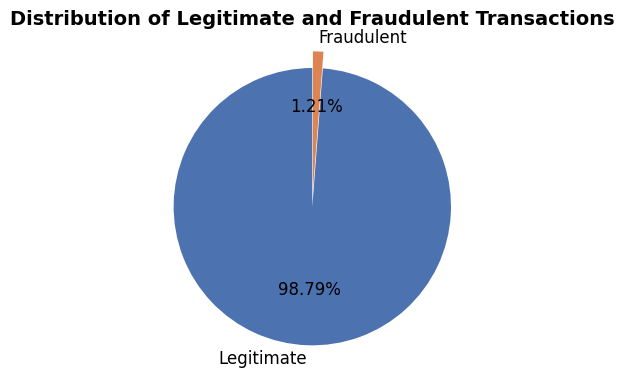

In [18]:
# Calculate the number of transactions in each class
fraud_counts = df["fraud"].value_counts().sort_index()

# Create the pie chart
plt.figure(figsize=(5, 4))

plt.pie(
    fraud_counts.values,
    labels=["Legitimate", "Fraudulent"],
    autopct="%1.2f%%",
    startangle=90,
    colors=["#4C72B0", "#DD8452"],
    explode=(0, 0.12),
    textprops={"fontsize": 12}
)

plt.title(
    "Distribution of Legitimate and Fraudulent Transactions",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### 📝 Key Takeaway — Class Imbalance

The dataset contains **587,443 legitimate transactions (approximately 98.79%)** and **7,200 fraudulent transactions (approximately 1.21%)**.

This confirms that fraud detection is a highly imbalanced classification problem. Accuracy alone may be misleading because a model can achieve a high accuracy while failing to identify fraudulent transactions.

Therefore, model evaluation will emphasize precision, recall, F1-score, and Precision-Recall AUC (PR-AUC). We will also investigate suitable methods for handling class imbalance during model training.

### 5.2 Transaction Amount Distribution

In [13]:
df["amount"].describe()

count    594643.000000
mean         37.890135
std         111.402831
min           0.000000
25%          13.740000
50%          26.900000
75%          42.540000
max        8329.960000
Name: amount, dtype: float64

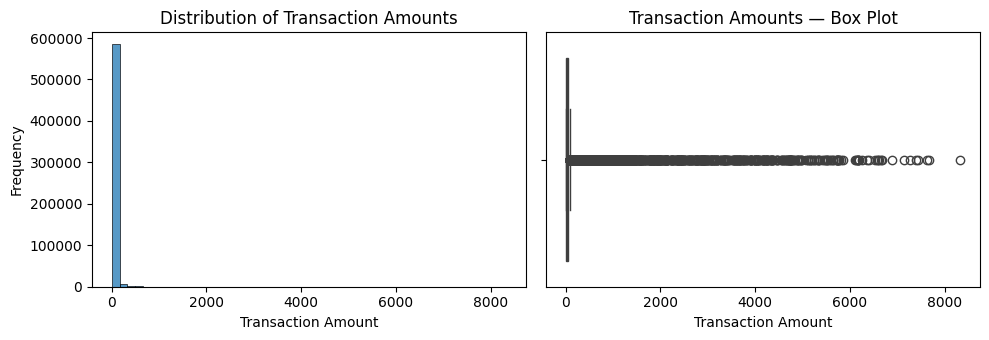

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

# Histogram
sns.histplot(
    data=df,
    x="amount",
    bins=50,
    ax=axes[0]
)
axes[0].set_title("Distribution of Transaction Amounts")
axes[0].set_xlabel("Transaction Amount")
axes[0].set_ylabel("Frequency")

# Box plot
sns.boxplot(
    data=df,
    x="amount",
    ax=axes[1]
)
axes[1].set_title("Transaction Amounts — Box Plot")
axes[1].set_xlabel("Transaction Amount")

plt.tight_layout()
plt.show()

In [18]:
amount_skewness = df["amount"].skew()
print(f"Transaction amount skewness: {amount_skewness:.3f}")

Transaction amount skewness: 32.366


### 📝 Key Takeaway — Transaction Amount Distribution

The transaction amount has a mean of **37.89** and a median of **26.90**, with a maximum value of **8,329.96**. The histogram shows that most transactions have relatively small amounts, while a smaller number of large transactions create a long right tail.

The box plot also identifies numerous potential statistical outliers. However, these values should not automatically be removed because large transactions can be legitimate and may contain useful information for fraud detection.

A logarithmic transformation will be explored to reduce skewness and compress extreme values. Its usefulness will be assessed before deciding whether to include the transformed feature in the final modeling pipeline.

In [19]:
# Calculate skewness before and after log transformation
original_skewness = df["amount"].skew()
log_skewness = np.log1p(df["amount"]).skew()

print(f"Original amount skewness : {original_skewness:.3f}")
print(f"Log-transformed skewness : {log_skewness:.3f}")

Original amount skewness : 32.366
Log-transformed skewness : -0.421


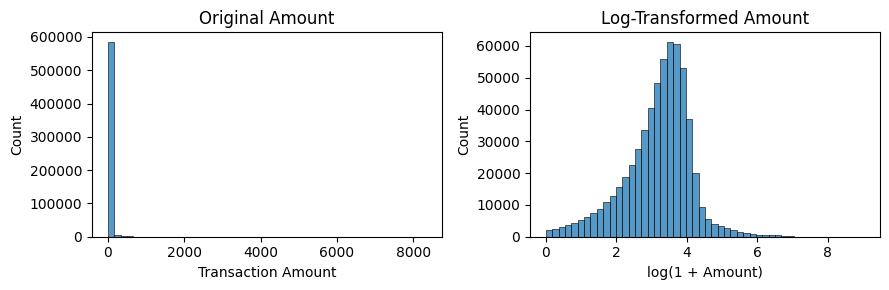

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3))

sns.histplot(
    df["amount"],
    bins=50,
    ax=axes[0]
)
axes[0].set_title("Original Amount")
axes[0].set_xlabel("Transaction Amount")

sns.histplot(
    np.log1p(df["amount"]),
    bins=50,
    ax=axes[1]
)
axes[1].set_title("Log-Transformed Amount")
axes[1].set_xlabel("log(1 + Amount)")

plt.tight_layout()
plt.show()

The original transaction amount has a skewness of approximately **32.366**, indicating an extremely right-skewed distribution. Applying the `log1p` transformation reduces the skewness to approximately **−0.421**, producing a distribution that is much closer to symmetric, with slight left-skewness.

This demonstrates that the logarithmic transformation substantially changes the distribution of transaction amounts.
However, reduced skewness alone does not guarantee improved model performance. The transformed feature will therefore be evaluated during model development rather than automatically replacing the original feature.

### 5.3 Fraud Analysis by Transaction Category

In this section, we will examine fraud across transaction categories to identify potential differences in fraud prevalence.

We will compare both the number of fraudulent transactions and the **fraud rate within each category**. This distinction is important because categories with more transactions may naturally have higher fraud counts simply due to their size.

> **Note:** Observed differences represent associations in this dataset and do not establish that a transaction category causes fraud.

In [21]:
# Count legitimate and fraudulent transactions in each category
category_counts = pd.crosstab(
    df["category"],
    df["fraud"]
).reindex(columns=[0, 1], fill_value=0)

# Rename columns for clarity
category_counts.columns = ["Legitimate", "Fraudulent"]

# Calculate total transactions and fraud rate for each category
category_counts["Total Transactions"] = (
    category_counts["Legitimate"] +
    category_counts["Fraudulent"]
)

category_counts["Fraud Rate (%)"] = (
    category_counts["Fraudulent"] /
    category_counts["Total Transactions"] * 100
)

# Display categories ordered by fraud rate
category_counts.sort_values(
    "Fraud Rate (%)",
    ascending=False
).round(2)

,Legitimate,Fraudulent,Total Transactions,Fraud Rate (%)
category,,,,
'es_leisure',25,474,499,94.99
'es_travel',150,578,728,79.40
'es_sportsandtoys',2020,1982,4002,49.53
'es_hotelservices',1196,548,1744,31.42
'es_otherservices',684,228,912,25.00
'es_home',1684,302,1986,15.21
'es_health',14437,1696,16133,10.51
'es_tech',2212,158,2370,6.67
'es_wellnessandbeauty',14368,718,15086,4.76


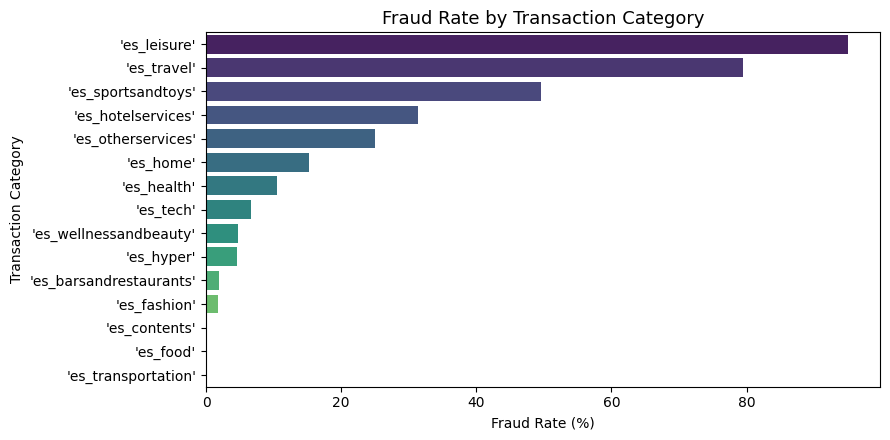

In [22]:
# Sort categories by their fraud rate
fraud_rate_by_category = category_counts.sort_values(
    "Fraud Rate (%)",
    ascending=False
)

plt.figure(figsize=(9, 4.5))

sns.barplot(
    data=fraud_rate_by_category.reset_index(),
    x="Fraud Rate (%)",
    y="category",
    hue="category",
    palette="viridis",
    legend=False
)

plt.title("Fraud Rate by Transaction Category", fontsize=13)
plt.xlabel("Fraud Rate (%)")
plt.ylabel("Transaction Category")
plt.tight_layout()
plt.show()

In [23]:
category_summary = category_counts[
    ["Total Transactions", "Fraudulent", "Fraud Rate (%)"]
].sort_values("Total Transactions", ascending=False)

category_summary.round(2)

,Total Transactions,Fraudulent,Fraud Rate (%)
category,,,
'es_transportation',505119,0,0.00
'es_food',26254,0,0.00
'es_health',16133,1696,10.51
'es_wellnessandbeauty',15086,718,4.76
'es_fashion',6454,116,1.80
'es_barsandrestaurants',6373,120,1.88
'es_hyper',6098,280,4.59
'es_sportsandtoys',4002,1982,49.53
'es_tech',2370,158,6.67


### 📝 Key Takeaway — Fraud by Transaction Category

Fraud prevalence varies considerably across transaction categories in the BankSim dataset. Categories such as `es_leisure`, `es_travel`, and `es_sportsandtoys` exhibit substantially higher fraud rates than several other categories.


### 5.4 Fraud Analysis by Transaction Amount

In this section, we will compare transaction amounts across the two target classes using descriptive statistics and a box plot. We will also examine their distributions on a logarithmic scale to make differences easier to visualize.

The goal is to determine whether transaction amounts show useful patterns associated with fraud, without assuming that amount alone can reliably identify fraudulent activity.

In [24]:
amount_summary = df.groupby("fraud")["amount"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

amount_summary.index = ["Legitimate", "Fraudulent"]

amount_summary.round(2)

,count,mean,median,std,min,max
Legitimate,587443,31.85,26.61,31.47,0.00,2144.86
Fraudulent,7200,530.93,319.18,835.59,0.03,8329.96


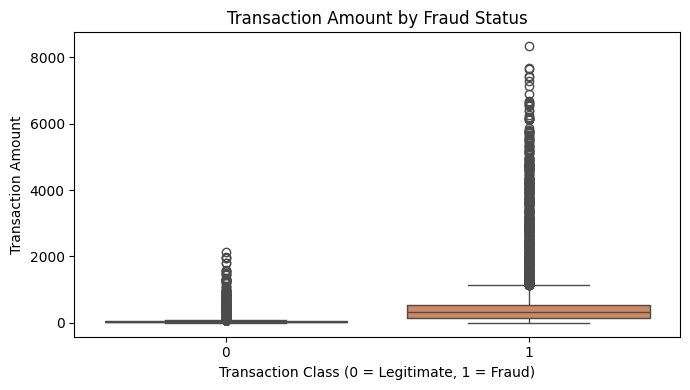

In [25]:
plt.figure(figsize=(7, 4))

sns.boxplot(
    data=df,
    x="fraud",
    y="amount",
    hue="fraud",
    palette=["#4C72B0", "#DD8452"],
    legend=False
)

plt.title("Transaction Amount by Fraud Status", fontsize=12)
plt.xlabel("Transaction Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Transaction Amount")

plt.tight_layout()
plt.show()

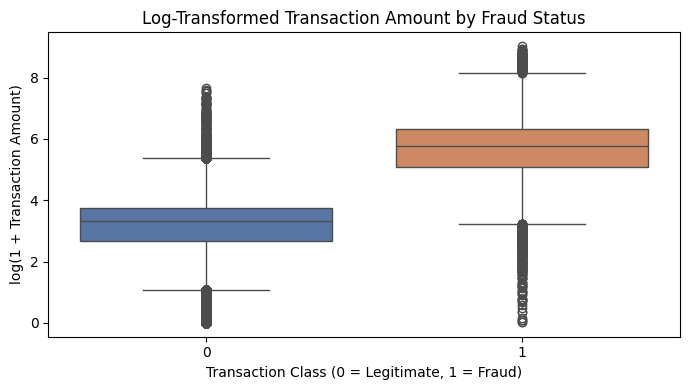

In [26]:
if "amount_log" not in df.columns:
    df["amount_log"] = np.log1p(df["amount"])

plt.figure(figsize=(7, 4))

sns.boxplot(
    data=df,
    x="fraud",
    y="amount_log",
    hue="fraud",
    palette=["#4C72B0", "#DD8452"],
    legend=False
)

plt.title("Log-Transformed Transaction Amount by Fraud Status", fontsize=12)
plt.xlabel("Transaction Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("log(1 + Transaction Amount)")

plt.tight_layout()
plt.show()

### 📝 Key Takeaway — Fraud Analysis by Transaction Amount

The analysis reveals a substantial difference between legitimate and fraudulent transaction amounts.

- **Legitimate transactions:** The mean amount is 31.85, with a median of 26.61.
- **Fraudulent transactions:** The mean amount is 530.93, with a median of 319.18.
- The fraudulent transaction amounts exhibit considerably greater variability, with a standard deviation of 835.59 compared with 31.47 for legitimate transactions.
- The box plots show that fraudulent transactions generally have higher amounts, although both groups contain potential outliers.
- The logarithmic transformation makes the distributions easier to compare and reveals a clear separation between the typical amounts of the two classes.

### 5.5 Fraud Patterns Across Time Steps

The `step` variable represents the time step associated with each transaction in the BankSim dataset. Examining this variable may help us identify temporal patterns in transaction activity and fraud prevalence.

In this section, we will:

- Examine how transaction volume changes across time steps.
- Compare legitimate and fraudulent transaction counts over time.
- Calculate the fraud rate at each time step.


In [28]:
# Calculate transaction counts by time step and fraud status
time_summary = pd.crosstab(
    df["step"],
    df["fraud"]
).reindex(columns=[0, 1], fill_value=0)

time_summary.columns = ["Legitimate", "Fraudulent"]

# Calculate total transactions and fraud rate per time step
time_summary["Total Transactions"] = (
    time_summary["Legitimate"] +
    time_summary["Fraudulent"]
)

time_summary["Fraud Rate (%)"] = (
    time_summary["Fraudulent"] /
    time_summary["Total Transactions"] * 100
)

time_summary.head()

,Legitimate,Fraudulent,Total Transactions,Fraud Rate (%)
step,,,,
0,2390,40,2430,1.646091
1,2384,40,2424,1.650165
2,2422,40,2462,1.624695
3,2459,40,2499,1.600640
4,2492,40,2532,1.579779


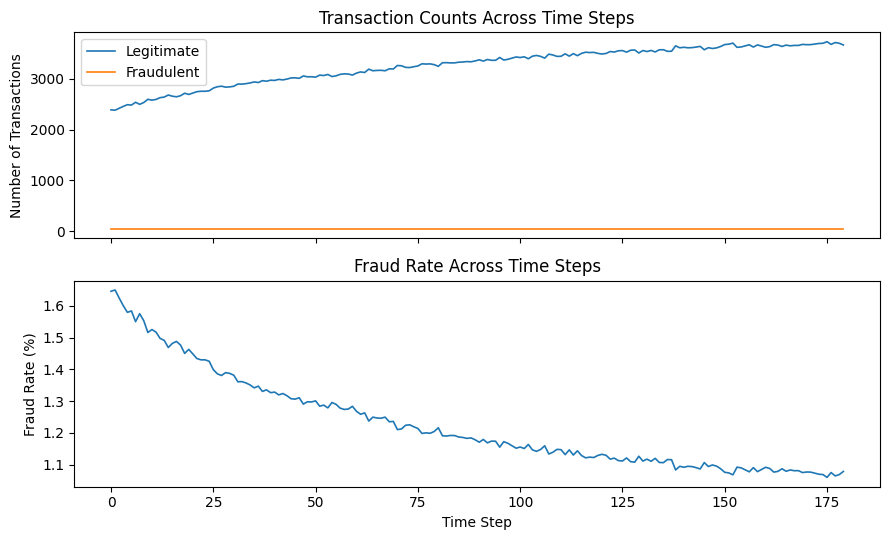

In [29]:
fig, axes = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True)

# Plot transaction counts
axes[0].plot(
    time_summary.index,
    time_summary["Legitimate"],
    label="Legitimate",
    linewidth=1.2
)

axes[0].plot(
    time_summary.index,
    time_summary["Fraudulent"],
    label="Fraudulent",
    linewidth=1.2
)

axes[0].set_title("Transaction Counts Across Time Steps")
axes[0].set_ylabel("Number of Transactions")
axes[0].legend()

# Plot fraud rate
axes[1].plot(
    time_summary.index,
    time_summary["Fraud Rate (%)"],
    linewidth=1.2
)

axes[1].set_title("Fraud Rate Across Time Steps")
axes[1].set_xlabel("Time Step")
axes[1].set_ylabel("Fraud Rate (%)")

plt.tight_layout()
plt.show()

In [30]:
print(
    f"Number of time steps: {df['step'].nunique()}"
)

print(
    f"Average fraud rate across transactions: "
    f"{df['fraud'].mean() * 100:.2f}%"
)

print(
    f"Minimum time-step fraud rate: "
    f"{time_summary['Fraud Rate (%)'].min():.2f}%"
)

print(
    f"Maximum time-step fraud rate: "
    f"{time_summary['Fraud Rate (%)'].max():.2f}%"
)

Number of time steps: 180
Average fraud rate across transactions: 1.21%
Minimum time-step fraud rate: 1.06%
Maximum time-step fraud rate: 1.65%


### 📝 Key Takeaway — Fraud Patterns Across Time Steps

The temporal analysis reveals that the BankSim dataset contains **180 simulation time steps**, with an overall fraud rate of **1.21%**.

- The fraud rate varies from approximately **1.06% to 1.65%** across individual time steps.
- The visualizations show that legitimate transaction volume generally increases over time, while fraudulent transaction counts remain relatively stable.
- Consequently, the fraud rate generally decreases as the simulation progresses, indicating that changes in transaction volume can affect the observed prevalence of fraud.

These findings suggest that fraud prevalence is not constant throughout the simulated timeline.

### 5.6 Fraud Analysis by Customer Gender

The BankSim dataset includes a `gender` feature representing the gender category associated with a customer.

In this section, we will compare transaction counts and fraud rates across the recorded gender categories to investigate whether any differences are present in the dataset.

In [32]:
# Count legitimate and fraudulent transactions by gender
gender_summary = pd.crosstab(
    df["gender"],
    df["fraud"]
).reindex(columns=[0, 1], fill_value=0)

gender_summary.columns = ["Legitimate", "Fraudulent"]

# Calculate total transactions and fraud rate
gender_summary["Total Transactions"] = (
    gender_summary["Legitimate"] +
    gender_summary["Fraudulent"]
)

gender_summary["Fraud Rate (%)"] = (
    gender_summary["Fraudulent"] /
    gender_summary["Total Transactions"] * 100
)

gender_summary.round(2)

,Legitimate,Fraudulent,Total Transactions,Fraud Rate (%)
gender,,,,
'E',1171,7,1178,0.59
'F',319807,4758,324565,1.47
'M',265950,2435,268385,0.91
'U',515,0,515,0.00


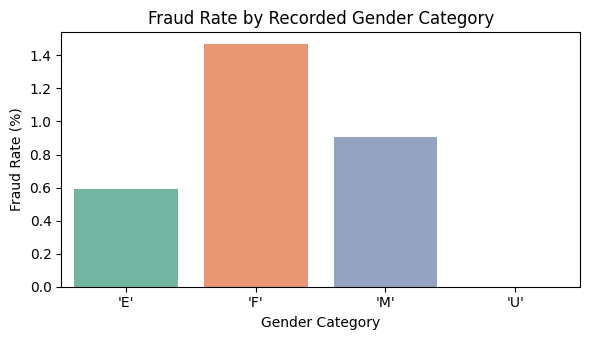

In [35]:
plt.figure(figsize=(6, 3.5))

sns.barplot(
    data=gender_summary.reset_index(),
    x="gender",
    y="Fraud Rate (%)",
    hue="gender",
    palette="Set2",
    legend=False
)

plt.title("Fraud Rate by Recorded Gender Category")
plt.xlabel("Gender Category")
plt.ylabel("Fraud Rate (%)")

plt.tight_layout()
plt.show()

### 📝 Key Takeaway — Fraud Analysis by Customer Gender

The analysis shows differences in observed fraud rates across the gender categories recorded in the BankSim dataset.

- **Category `F`** has the highest observed fraud rate at **1.47%**, followed by category `M` at **0.91%**.
- Category `E` has a fraud rate of **0.59%**, while category `U` has no recorded fraudulent transactions among its 515 transactions.
- Category `F` also accounts for the largest number of fraudulent transactions (4,758), partly because it has the largest transaction volume among these groups.

These findings indicate an association between the recorded gender category and fraud prevalence in this synthetic dataset.

## 5.7 Summary of Exploratory Data Analysis

The exploratory data analysis revealed several important characteristics of the BankSim dataset:

1. **Class imbalance:** Fraudulent transactions represent approximately 1.21% of all transactions, making this an imbalanced classification problem.
2. **Transaction amounts:** Fraudulent transactions have substantially higher mean and median amounts than legitimate transactions in this dataset. The original amount distribution is strongly right-skewed.
3. **Transaction categories:** Fraud rates vary considerably across categories, suggesting that transaction type may be informative for classification.
4. **Temporal patterns:** Fraud prevalence varies across the 180 simulation time steps, decreasing overall as legitimate transaction volume increases.
5. **Recorded gender categories:** Observed fraud rates differ across the recorded categories, but these associations require careful ethical interpretation.

### Implications for Modeling

These findings guide the next stages of the project. We will account for class imbalance, evaluate transaction amount and category as potential predictors, handle categorical features appropriately, and prevent data leakage during preprocessing and evaluation.

The dataset is synthetic, so the observed patterns should not be assumed to represent real-world fraud behavior without further validation.

## 6. Feature Engineering

Feature engineering involves selecting, transforming, or creating input variables that help machine learning models learn meaningful patterns.

Before constructing new features, we will classify the existing columns by their roles. This is particularly important because customer identifiers, merchant identifiers, and location codes should not automatically be treated as ordinary numerical measurements.

We will also keep the target variable `fraud` separate from the input features to prevent target leakage.

In [36]:
# Inspect the existing columns and their data types
feature_overview = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Unique Values": [
        df[col].nunique() for col in df.columns
    ]
})

feature_overview

,Column,Data Type,Unique Values
0,step,int64,180
1,customer,object,4112
2,age,object,8
3,gender,object,4
4,zipcodeOri,object,1
5,merchant,object,50
6,zipMerchant,object,1
7,category,object,15
8,amount,float64,23767
9,fraud,int64,2


In [37]:
# Compare the original and log-transformed transaction amounts
df[["amount", "amount_log"]].head(10)

,amount,amount_log
0,4.55,1.713798
1,39.68,3.705737
2,26.89,3.328268
3,17.25,2.904165
4,35.72,3.603322
5,25.81,3.288775
6,9.10,2.312535
7,21.17,3.098740
8,32.40,3.508556
9,35.40,3.594569


In [39]:
# Identify columns with only one unique value
constant_columns = [
    col for col in df.columns
    if df[col].nunique() == 1
]

print("Constant columns:", constant_columns)

Constant columns: ['zipcodeOri', 'zipMerchant']


### 📝 Feature Engineering — Initial Decisions

Based on the feature inspection, we identified the following considerations:

- **Constant features:** `zipcodeOri` and `zipMerchant` contain only one unique value each and will be excluded from modeling.
- **Transaction amount:** Both `amount` and `amount_log` are available. The log transformation is mathematically correct and may help reduce the influence of extreme values. We will compare the usefulness of these representations rather than automatically including both.
- **Categorical features:** `age`, `gender`, and `category` will be treated as categorical variables.
- **Identifiers:** `customer` and `merchant` require careful handling because their values identify entities rather than directly measuring transaction behavior.
- **Temporal feature:** `step` represents the simulation's time step and may contain useful temporal information.
- **Target variable:** `fraud` will be kept separate from the input features to prevent target leakage.

These decisions are preliminary. The final feature set will be defined before training, with all learned preprocessing fitted only on the training data.

### 6.4 Defining the Initial Feature Groups

Before building machine learning models, we organize the available variables according to their roles.
For the initial modeling approach:

- **Numerical features:** `step` and `amount` (or its log-transformed alternative, `amount_log`).
- **Categorical features:** `age`, `gender`, and `category`.
- **Identifiers:** `customer` and `merchant`, which require careful treatment.
- **Excluded constant features:** `zipcodeOri` and `zipMerchant`.
- **Target variable:** `fraud`.

The final feature selection will be performed before model training, and the test set will remain untouched during model selection and tuning.

In [40]:
# Columns that provide no variation
constant_columns = ["zipcodeOri", "zipMerchant"]

# Initial transaction-level features
numerical_features = ["step", "amount_log"]

categorical_features = ["age", "gender", "category"]

# Combine input features
feature_columns = numerical_features + categorical_features

# Separate features and target
X = df[feature_columns].copy()
y = df["fraud"].copy()

print("Number of input features:", X.shape[1])
print("Input features:", feature_columns)
print("Target shape:", y.shape)

Number of input features: 5
Input features: ['step', 'amount_log', 'age', 'gender', 'category']
Target shape: (594643,)


## 7. Train-Test Split

We divide the dataset into training and testing subsets using an 80:20 split.

- **Training set (80%):** Used to fit the machine learning models and learn patterns from transaction features.
- **Testing set (20%):** Reserved for evaluating the selected model on unseen transactions.

The test set will not be used for feature selection, preprocessing fitting, hyperparameter tuning, or decision-threshold selection.

In [41]:
from sklearn.model_selection import train_test_split

# Split features and target into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Check the dimensions of each subset
print("Training features:", X_train.shape)
print("Testing features :", X_test.shape)
print("Training target  :", y_train.shape)
print("Testing target   :", y_test.shape)

Training features: (475714, 5)
Testing features : (118929, 5)
Training target  : (475714,)
Testing target   : (118929,)


In [42]:
# Compare fraud percentages in the original, training, and testing sets
split_distribution = pd.DataFrame({
    "Original Dataset": y.value_counts(normalize=True),
    "Training Set": y_train.value_counts(normalize=True),
    "Testing Set": y_test.value_counts(normalize=True)
}).sort_index()

split_distribution.index = ["Legitimate (0)", "Fraudulent (1)"]

(split_distribution * 100).round(3)

,Original Dataset,Training Set,Testing Set
Legitimate (0),98.789,98.789,98.789
Fraudulent (1),1.211,1.211,1.211


### 📝 Key Takeaway — Train-Test Split

The dataset was divided into training and testing subsets using an 80:20 stratified split.

- **Training set:** 475,714 transactions with 5 input features.
- **Testing set:** 118,929 transactions with 5 input features.
- **Class distribution:** Both subsets preserve the original distribution of approximately 98.789% legitimate transactions and 1.211% fraudulent transactions.

Stratification ensures that the minority fraud class remains proportionally represented in both subsets. The fixed random state makes the split reproducible.

## 8. Data Preprocessing

Preprocessing transforms raw input features into a representation suitable for machine learning algorithms.

In this project, we will use:

1. **StandardScaler** to standardize numerical features.
2. **OneHotEncoder** to convert categorical features into numerical indicator columns.
3. **ColumnTransformer** to apply the correct transformation to each feature group.
4. **Pipeline** to combine preprocessing and model training into a single workflow.

The preprocessing components will be fitted only on the training data. The same fitted transformations will then be applied to validation and test data, preventing information from the test set from influencing the learned preprocessing parameters.

We will use `handle_unknown="ignore"` in the encoder so that previously unseen categories can be handled safely during prediction.

In [43]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

In [44]:
# Numerical preprocessing
numerical_transformer = StandardScaler()

# Categorical preprocessing
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

# Apply transformations to the appropriate columns
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline components created successfully.")

Preprocessing pipeline components created successfully.


In [45]:
# Fit on training data and transform it
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data using the already-fitted preprocessor
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape :", X_test_processed.shape)

Processed training shape: (475714, 29)
Processed testing shape : (118929, 29)


## 🤖 6. Establishing a Baseline Model

Before training actual machine learning models, we establish a baseline using a **Dummy Classifier**.

A Dummy Classifier makes predictions using a simple predefined strategy rather than learning meaningful patterns from the transaction data.

Since approximately **98.79% of transactions are legitimate**, a classifier that always predicts the majority class could achieve nearly 98.79% accuracy while failing to identify any fraudulent transactions.

This baseline demonstrates why accuracy alone is misleading for an imbalanced fraud detection problem.

**Objective:** Compare a simple majority-class prediction strategy against the performance of more advanced models developed later in this project.

### Train the baseline model

In [46]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Create a majority-class baseline model
dummy_model = DummyClassifier(strategy="most_frequent")

# Train the baseline model
dummy_model.fit(X_train_processed, y_train)

# Generate predictions on the test set
y_pred_dummy = dummy_model.predict(X_test_processed)

# Calculate baseline metrics
baseline_results = {
    "Accuracy": accuracy_score(y_test, y_pred_dummy),
    "Precision": precision_score(y_test, y_pred_dummy, zero_division=0),
    "Recall": recall_score(y_test, y_pred_dummy, zero_division=0),
    "F1-Score": f1_score(y_test, y_pred_dummy, zero_division=0),
    "Average Precision": average_precision_score(
        y_test, dummy_model.predict_proba(X_test_processed)[:, 1]
    )
}

pd.Series(baseline_results).round(4)

Accuracy             0.9879
Precision            0.0000
Recall               0.0000
F1-Score             0.0000
Average Precision    0.0121
dtype: float64

### Inspect the confusion matrix

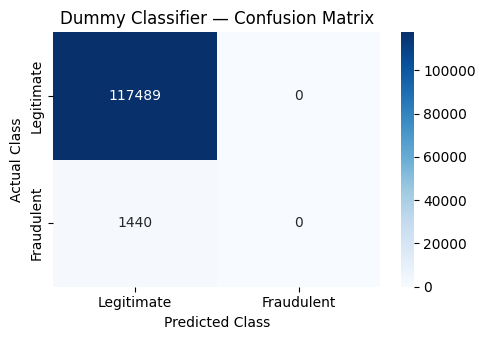

In [47]:
plt.figure(figsize=(5, 3.5))

sns.heatmap(
    confusion_matrix(y_test, y_pred_dummy),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraudulent"],
    yticklabels=["Legitimate", "Fraudulent"]
)

plt.title("Dummy Classifier — Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

### 📝 Key Takeaways

The Dummy Classifier achieved **98.79% accuracy** by predicting every transaction as legitimate. However, it achieved **0% precision, 0% recall, and 0% F1-score** because it failed to identify any fraudulent transactions.

The confusion matrix confirms that all 1,440 fraudulent transactions in the test set were missed.

This experiment demonstrates that accuracy is insufficient for evaluating a highly imbalanced fraud detection problem. Consequently, this project will prioritize **Recall, Precision, F1-score, and Average Precision (PR-AUC-related evaluation)** when comparing machine learning models.

The Dummy Classifier establishes a baseline that subsequent models must improve upon, particularly in their ability to detect fraudulent transactions.